In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Make matplotlib render at higher resolution by default
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

In [3]:
filenames = [ "Vortex-small/power_t/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz"]

In [ ]:
#avg_power = np.mean(data, axis=0)

In [ ]:
for fname in filenames:
    IR_sample = np.load(fname)
    data = IR_sample['data']

    print(IR_sample.files)
    print(data.shape)

    # --- Plot the 20 temporal slices ---
    for i in range(20):
        fig, ax = plt.subplots(figsize=(6, 6), dpi=200)

        im = ax.imshow(data[i, :, :], interpolation='nearest')
        ax.set_title(f"Time-Decomposed Power – Slice {i}", fontsize=14)
        ax.axis("off")

        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        plt.tight_layout()
        plt.show()

    # --- Compute and plot average over 20 slices ---
    avg_power = np.mean(data, axis=0)

    fig, ax = plt.subplots(figsize=(6, 6), dpi=200)

    im = ax.imshow(avg_power, interpolation='nearest')
    ax.set_title("Average Temporal Power", fontsize=14)
    ax.axis("off")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

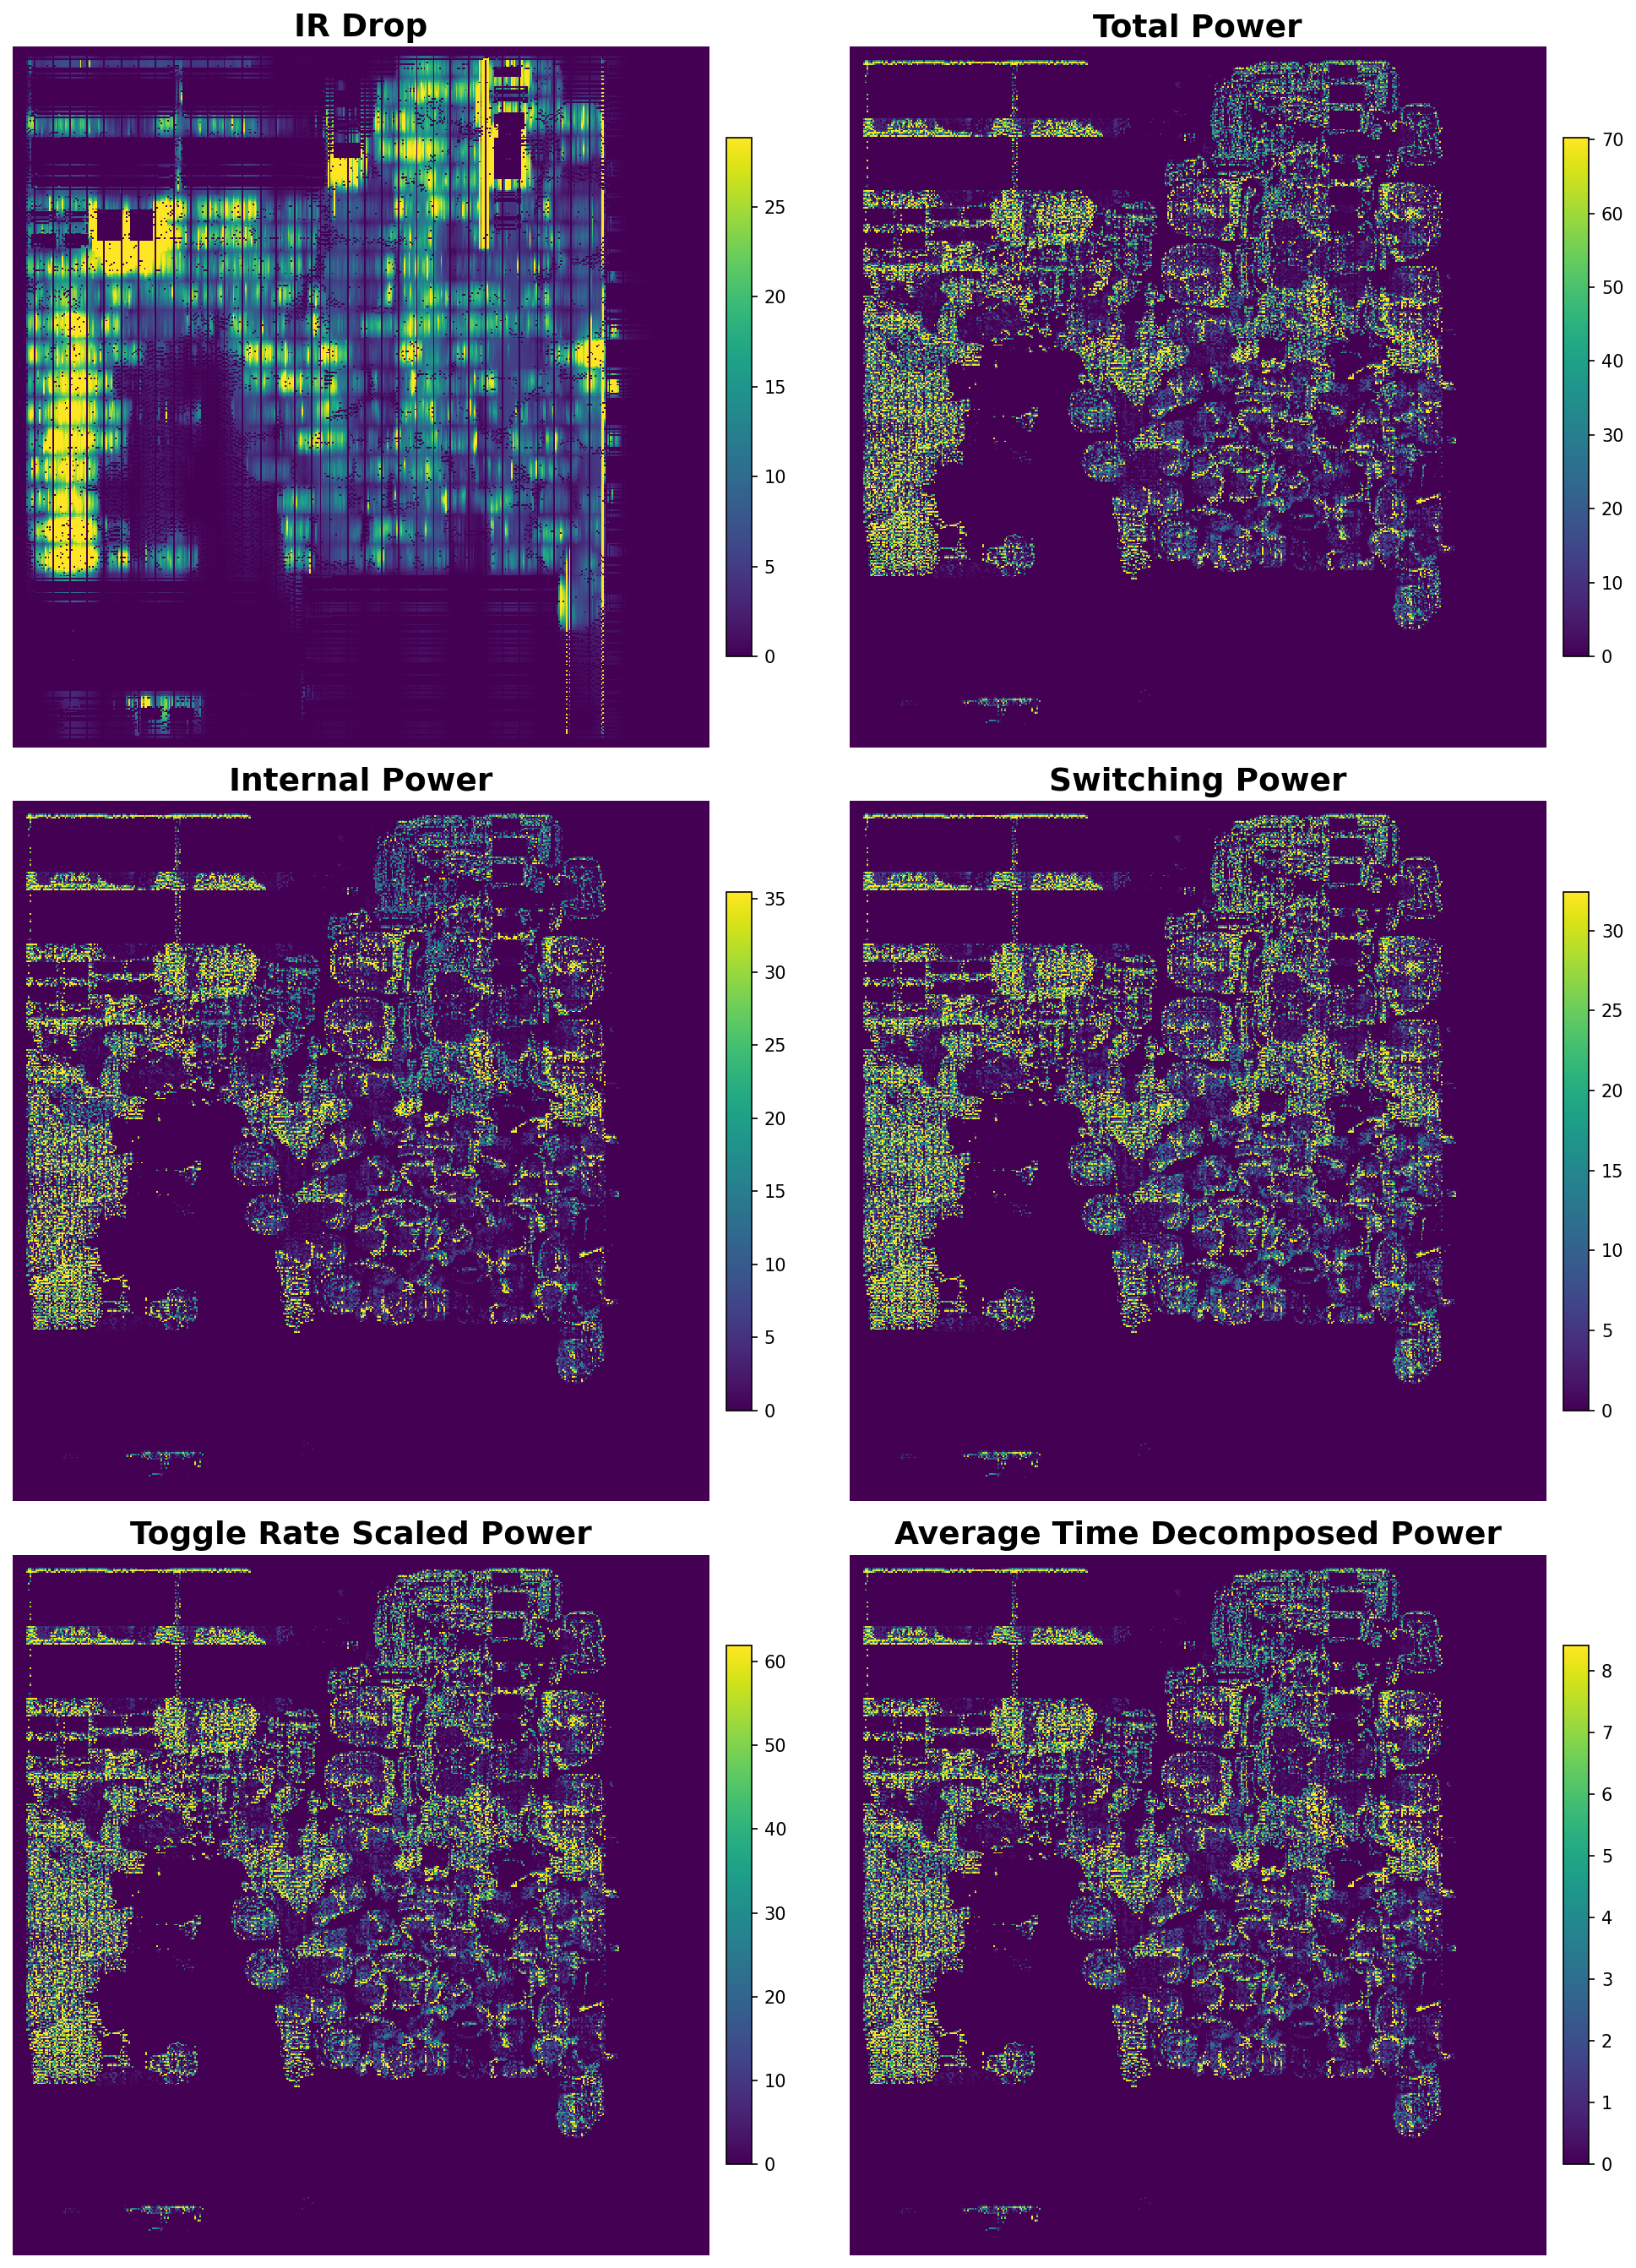

In [8]:
# --- Load all data ---
ir_data = np.load("Vortex-small/IR_drop/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']
total_power = np.load("Vortex-small/power_all/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']
internal_power = np.load("Vortex-small/power_i/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']
switching_power = np.load("Vortex-small/power_s/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']
scaled_switching_power = np.load("Vortex-small/power_sca/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']

# --- Load temporal and average ---
power_t = np.load("Vortex-small/power_t/Vortex-small_freq_200_mp_1_fpu_50_fpa_1.0_p_2_fi_ap.npz")['data']
avg_temporal_power = np.mean(power_t, axis=0)

# --- Create 3x2 grid ---
fig, axs = plt.subplots(3, 2, figsize=(14, 18))
axs = axs.flatten()

# List of data + titles
maps = [
    (ir_data, "IR Drop"),
    (total_power, "Total Power"),
    (internal_power, "Internal Power"),
    (switching_power, "Switching Power"),
    (scaled_switching_power, "Toggle Rate Scaled Power"),
    (avg_temporal_power, "Average Time Decomposed Power")
]

# Plot everything
for i, (data, title) in enumerate(maps):
    ax = axs[i]
    
    # Reduce max color value for better contrast
    vmax = np.percentile(data, 97)

    im = ax.imshow(data, interpolation='nearest', vmax=vmax)
    ax.set_title(title, fontsize=18, fontweight='bold')
    ax.axis("off")

    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

plt.tight_layout()
plt.show()

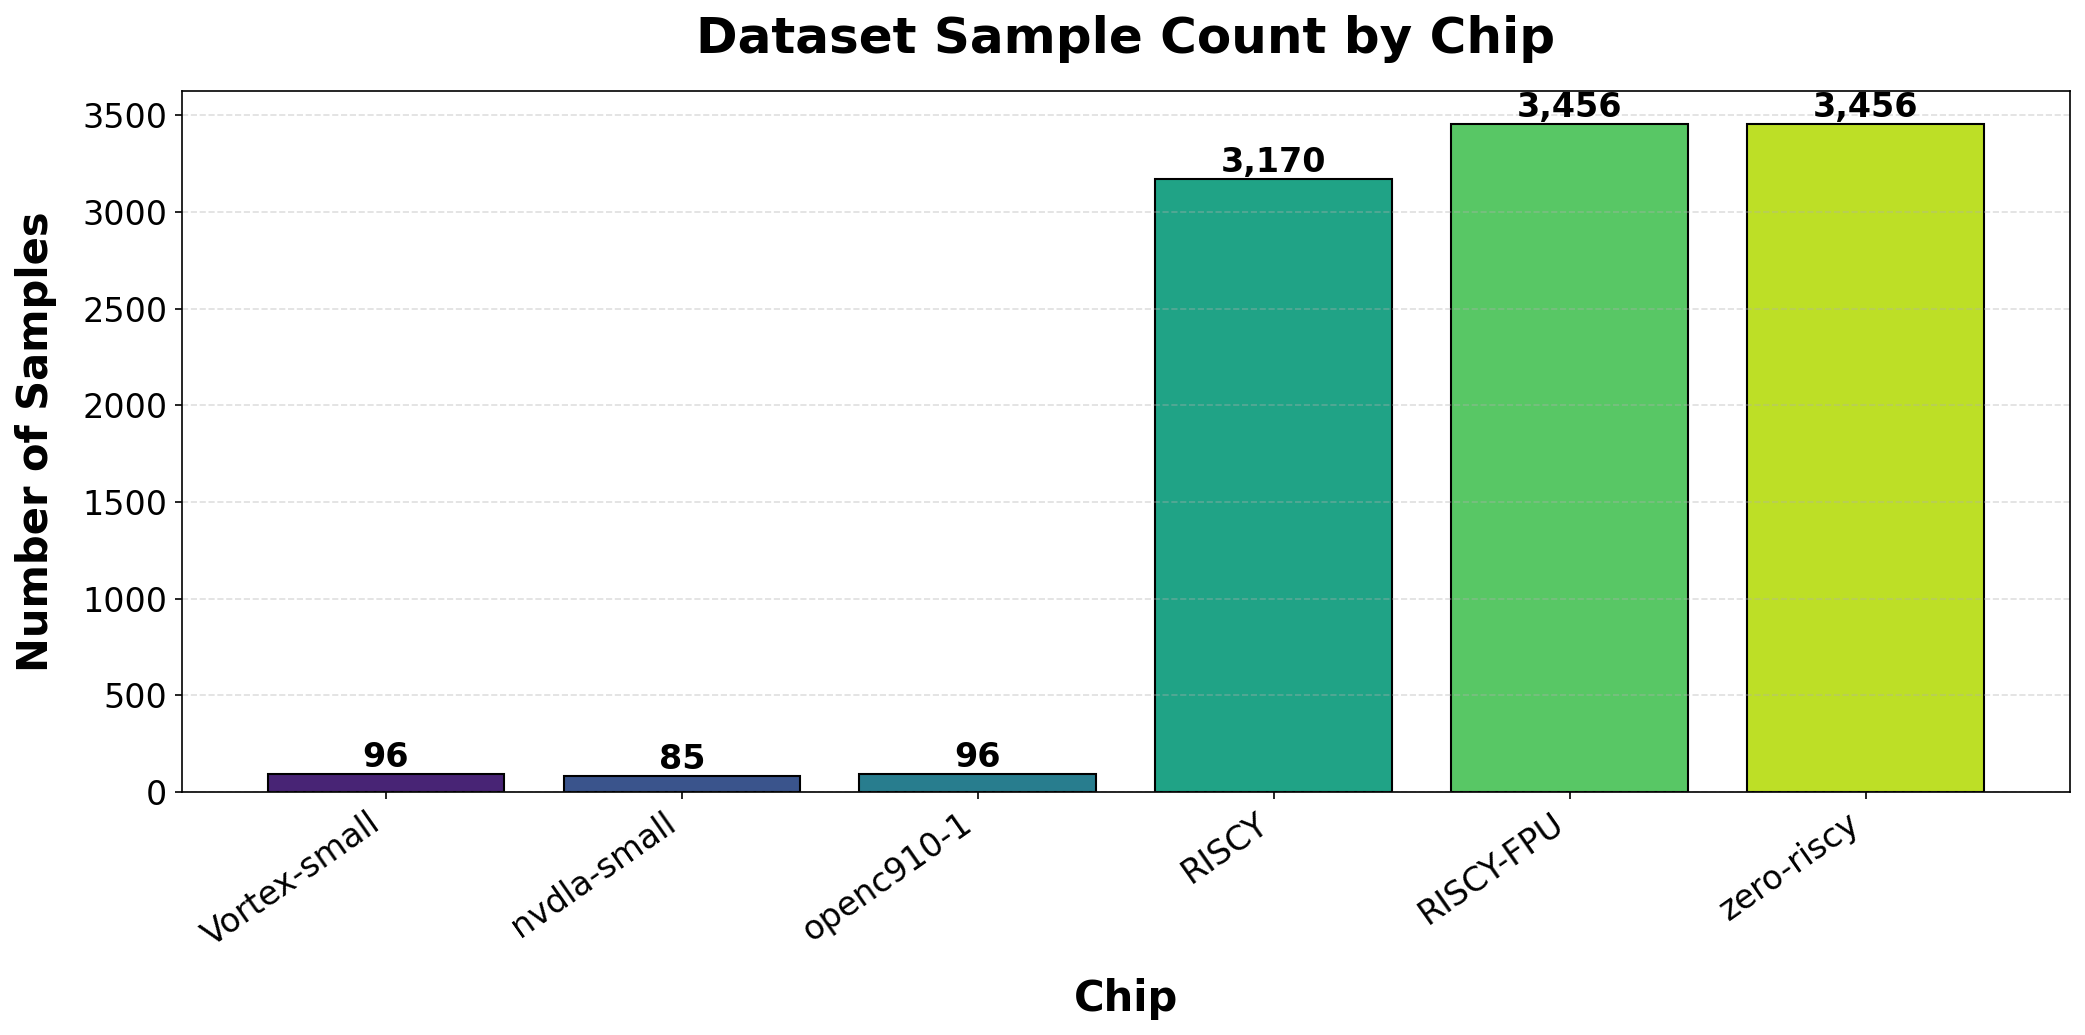

In [7]:
from pathlib import Path

CHIPS = [
    "Vortex-small",
    #"Vortex-large",
    #"nvdla-large",
    "nvdla-small",
    "openc910-1",
    "RISCY",
    "RISCY-FPU",
    "zero-riscy",
]

chip_counts = [
    len(list(Path(chip, "IR_drop").glob("*.npz")))
    for chip in CHIPS
]

fig, ax = plt.subplots(figsize=(14, 7), dpi=150)

bars = ax.bar(
    CHIPS,
    chip_counts,
    color=plt.cm.viridis(np.linspace(0.1, 0.9, len(CHIPS))),
    edgecolor="black",
)

for bar, count in zip(bars, chip_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
    )

ax.set_title(
    "Dataset Sample Count by Chip",
    fontsize=24,
    fontweight="bold",
    pad=18,
)
ax.set_xlabel("Chip", fontsize=20, fontweight="bold", labelpad=12)
ax.set_ylabel("Number of Samples", fontsize=20, fontweight="bold", labelpad=12)

ax.tick_params(axis="x", labelsize=16, rotation=35)
ax.tick_params(axis="y", labelsize=16)

# Align rotated x-axis labels
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()